# Activity No. 1 — Machine Learning Classification and Regression

**Name:** Ojas Wankhede | **Div:** E | **Batch:** E1 | **Roll No:** 318 | **PRN:** 202401040326


**Dataset:** NASA C-MAPSS Turbofan Engine Degradation Simulation Data Set (FD001–FD004), NASA Ames Prognostics Center of Excellence (official source). Citation: A. Saxena and K. Goebel (2008), *Turbofan Engine Degradation Simulation Data Set*, NASA Ames Prognostics Data Repository.

**Objective:** Apply supervised machine learning to run-to-failure engine sensor data:
1. **Classification:** predict whether an engine will fail within the next 30 cycles.
2. **Regression:** estimate the Remaining Useful Life (RUL) in cycles.

## 1. Problem Definition

### Classification
For an engine observed at cycle $t$ with failure at cycle $T$:

$$Y_{30} = \begin{cases} 1 & \text{if } T - t \le 30 \\ 0 & \text{otherwise} \end{cases}$$

### Regression
$$RUL_t = T - t$$

The regression target is capped at 125 cycles (a standard practice, since early-life degradation is not observable in sensors).

## 2. Imports and configuration

In [7]:
from pathlib import Path
import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score)

RANDOM_STATE = 42
HORIZON = 30          # classification horizon (cycles)
RUL_CAP = 125         # regression cap
ROLL = 5              # rolling window (cycles)
RAW_DIR = Path("data")            # folder containing train_FD00x.txt, test_FD00x.txt, RUL_FD00x.txt
OUTPUT_DIR = Path("outputs"); OUTPUT_DIR.mkdir(exist_ok=True)

## 3. Locate and load the original files

The NASA files are space-separated text files without headers. Columns: unit, cycle, 3 operating settings, 21 sensors.

In [8]:
from pathlib import Path

RAW_DIR = Path(r"C:\Users\manoj\OneDrive\Desktop\AI-ML\I.A\IA-2\data")

print("Data folder:", RAW_DIR)
print("Files:", sorted(p.name for p in RAW_DIR.iterdir()))

Data folder: C:\Users\manoj\OneDrive\Desktop\AI-ML\I.A\IA-2\data
Files: ['Damage Propagation Modeling.pdf', 'RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'readme.txt', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']


In [9]:
cols = ["unit", "cycle"] + [f"setting_{i}" for i in (1, 2, 3)] + [f"s_{i}" for i in range(1, 22)]

def load(kind, fd):
    df = pd.read_csv(RAW_DIR / f"{kind}_FD00{fd}.txt", sep=r"\s+", header=None, names=cols)
    df["subset"] = f"FD00{fd}"
    df["unit_id"] = df["subset"] + "_" + df["unit"].astype(str)   # unique across subsets
    return df

train_raw = pd.concat([load("train", i) for i in range(1, 5)], ignore_index=True)
test_raw  = pd.concat([load("test", i) for i in range(1, 5)], ignore_index=True)
rul_true = pd.concat([
    pd.read_csv(RAW_DIR / f"RUL_FD00{i}.txt", header=None, names=["RUL"]).assign(
        unit_id=lambda d: f"FD00{i}_" + (d.index + 1).astype(str)) for i in range(1, 5)], ignore_index=True)
print(train_raw.shape, test_raw.shape, rul_true.shape)
train_raw.head()

(160359, 28) (104897, 28) (707, 2)


,unit,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21,subset,unit_id
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,FD001,FD001_1
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,FD001,FD001_1
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,FD001,FD001_1
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,FD001,FD001_1
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,FD001,FD001_1


## 4. Inspect the source data

In [10]:
summary = train_raw.groupby("subset").agg(rows=("unit", "size"), engines=("unit_id", "nunique"),
                                         max_cycle=("cycle", "max"))
display(summary)
print("Missing values:", int(train_raw.isna().sum().sum()))
std = train_raw[[c for c in cols if c.startswith(("s_", "setting"))]].std()
constant = std[std < 1e-6].index.tolist()
print("Constant (uninformative) columns:", constant)
display(train_raw.describe().T.head(12))

,rows,engines,max_cycle
subset,,,
FD001,20631,100,362
FD002,53759,260,378
FD003,24720,100,525
FD004,61249,249,543


Missing values: 0
Constant (uninformative) columns: []


,count,mean,std,min,25%,50%,75%,max
unit,160359.0,105.553758,72.867325,1.0000,44.0000,89.0000,164.0000,260.000
cycle,160359.0,123.331338,83.538146,1.0000,57.0000,114.0000,173.0000,543.000
setting_1,160359.0,17.211973,16.527988,-0.0087,0.0013,19.9981,35.0015,42.008
setting_2,160359.0,0.410004,0.367938,-0.0006,0.0002,0.6200,0.8400,0.842
setting_3,160359.0,95.724344,12.359044,60.0000,100.0000,100.0000,100.0000,100.000
s_1,160359.0,485.840890,30.420388,445.0000,449.4400,489.0500,518.6700,518.670
s_2,160359.0,597.361022,42.478516,535.4800,549.9600,605.9300,642.3400,645.110
s_3,160359.0,1467.035653,118.175261,1242.6700,1357.3600,1492.8100,1586.5900,1616.910
s_4,160359.0,1260.956434,136.300073,1023.7700,1126.8300,1271.7400,1402.2000,1441.490
s_5,160359.0,9.894999,4.265554,3.9100,5.4800,9.3500,14.6200,14.620


## 5. Construct targets and engineer features

- `RUL` = last cycle of the engine − current cycle (training files run to failure).
- `fail_next_30` = 1 if `RUL <= 30`.
- `RUL_capped` = `min(RUL, 125)` is the regression target.
- Features: current sensor values, operating settings, cycle number, and rolling mean/std over the last 5 cycles per engine (past data only, no leakage). Constant columns are dropped.

In [11]:
sensor_cols = [c for c in cols if c.startswith("s_") and c not in constant]
setting_cols = [c for c in cols if c.startswith("setting") and c not in constant]
base_feats = sensor_cols + setting_cols

def engineer(df):
    df = df.sort_values(["unit_id", "cycle"]).reset_index(drop=True)
    g = df.groupby("unit_id")[sensor_cols]
    roll_mean = g.rolling(ROLL, min_periods=1).mean().reset_index(level=0, drop=True)
    roll_std = g.rolling(ROLL, min_periods=2).std().reset_index(level=0, drop=True)
    roll_mean.columns = [c + "_rmean" for c in sensor_cols]
    roll_std.columns = [c + "_rstd" for c in sensor_cols]
    return pd.concat([df, roll_mean.sort_index(), roll_std.sort_index()], axis=1)

train = engineer(train_raw)
train["RUL"] = train.groupby("unit_id")["cycle"].transform("max") - train["cycle"]
train["fail_next_30"] = (train["RUL"] <= HORIZON).astype(int)
train["RUL_capped"] = train["RUL"].clip(upper=RUL_CAP)

feature_cols = base_feats + [c + s for c in sensor_cols for s in ("_rmean", "_rstd")] + ["cycle"]
cat_cols = ["subset"]
print("Rows:", len(train), "| Features:", len(feature_cols) + len(cat_cols))

Rows: 160359 | Features: 68


## 6. Classification target distribution

,rows
fail_next_30,
0,138380
1,21979


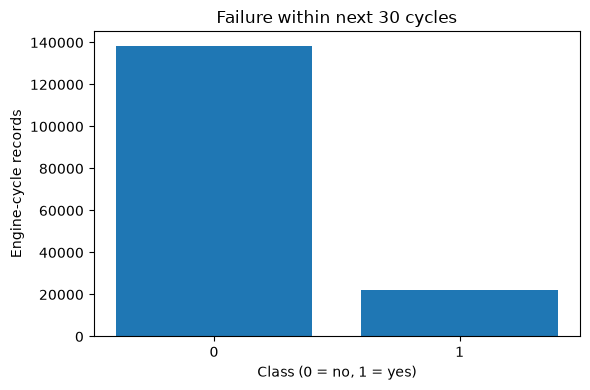

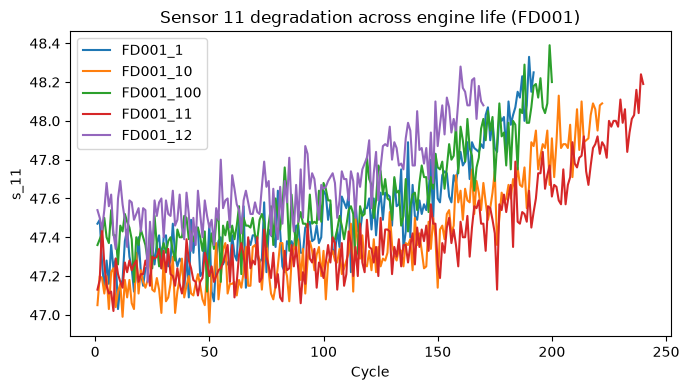

In [12]:
counts = train["fail_next_30"].value_counts().sort_index()
display(counts.to_frame("rows"))
plt.figure(figsize=(6, 4)); plt.bar(counts.index.astype(str), counts.values)
plt.title("Failure within next 30 cycles"); plt.xlabel("Class (0 = no, 1 = yes)"); plt.ylabel("Engine-cycle records")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))
for u in train[train.subset == "FD001"].unit_id.unique()[:5]:
    d = train[train.unit_id == u]; plt.plot(d["cycle"], d["s_11"], label=u)
plt.title("Sensor 11 degradation across engine life (FD001)"); plt.xlabel("Cycle"); plt.ylabel("s_11"); plt.legend()
plt.tight_layout(); plt.show()

## 7. Group-based split by engine

All cycles of an engine go to exactly one split (train 60% / validation 20% / test 20%) so the same engine never appears in two sets.

In [13]:
groups = train["unit_id"]
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
trval_idx, test_idx = next(gss1.split(train, groups=groups))
trval = train.iloc[trval_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
tr_i, va_i = next(gss2.split(trval, groups=trval["unit_id"]))
train_df, valid_df, test_df = trval.iloc[tr_i], trval.iloc[va_i], train.iloc[test_idx]
for n, d in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    print(f"{n:6s} rows={len(d):6d} engines={d.unit_id.nunique():4d} positive_rate={d.fail_next_30.mean():.3f}")

# Pipeline: impute numeric (rolling std is NaN on first cycle); one-hot subset via pandas get_dummies for simplicity
def make_X(d):
    X = d[feature_cols].copy()
    for s in sorted(train["subset"].unique()):
        X[f"subset_{s}"] = (d["subset"] == s).astype(int)
    return X
X_train, X_valid, X_test = make_X(train_df), make_X(valid_df), make_X(test_df)
imputer = SimpleImputer(strategy="median").fit(X_train)
def prep(X): return pd.DataFrame(imputer.transform(X), columns=X.columns, index=X.index)
X_train, X_valid, X_test = prep(X_train), prep(X_valid), prep(X_test)

train  rows= 96879 engines= 425 positive_rate=0.136
valid  rows= 32150 engines= 142 positive_rate=0.137
test   rows= 31330 engines= 142 positive_rate=0.141


## 8. Classification: train Random Forest

In [14]:
y_train, y_valid, y_test = train_df.fail_next_30, valid_df.fail_next_30, test_df.fail_next_30
classifier = RandomForestClassifier(n_estimators=60, min_samples_leaf=5, max_features="sqrt", class_weight="balanced_subsample",
                                    n_jobs=-1, random_state=RANDOM_STATE)
classifier.fit(X_train, y_train)
print("Trained. Features:", X_train.shape[1])

Trained. Features: 71


## 9. Classification: choose the decision threshold

The threshold maximising F1 on the **validation** set is selected; the test set is not used for this.

In [15]:
valid_prob = classifier.predict_proba(X_valid)[:, 1]
p, r, th = precision_recall_curve(y_valid, valid_prob)
f1v = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
selected_threshold = float(th[int(np.argmax(f1v))])
print("Validation-selected threshold:", round(selected_threshold, 4))
print("Validation average precision:", round(average_precision_score(y_valid, valid_prob), 4))

Validation-selected threshold: 0.5882
Validation average precision: 0.9424


## 10. Classification: final test evaluation

,value
ROC_AUC,0.989475
Average_Precision,0.948026
Precision,0.880019
Recall,0.851431
F1,0.865489
Test_rows,31330.000000
Test_engines,142.000000
Threshold,0.588160


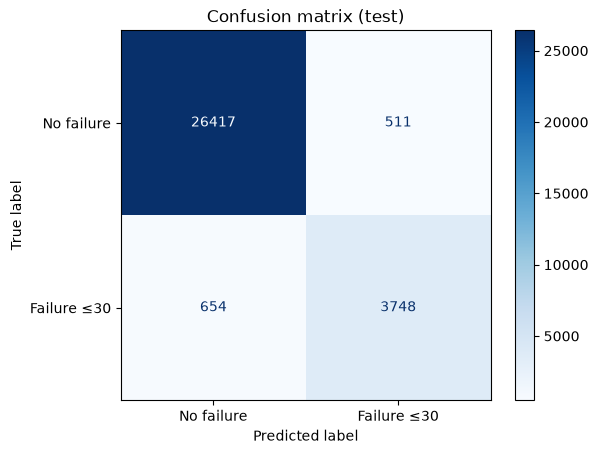

In [16]:
test_prob = classifier.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)
classification_metrics = {
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "Average_Precision": average_precision_score(y_test, test_prob),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "Test_rows": int(len(y_test)), "Test_engines": int(test_df.unit_id.nunique()),
    "Threshold": selected_threshold}
display(pd.Series(classification_metrics).to_frame("value"))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=["No failure", "Failure ≤30"]).plot(cmap="Blues")
plt.title("Confusion matrix (test)"); plt.show()

## 11. Classification: feature importance

Permutation importance: $I_j = AP_{original} - AP_{shuffled(j)}$ on a validation subset (model-specific, not causal).

,feature,importance_mean,importance_std
66,cycle,0.062233,0.003138
10,s_11,0.048530,0.005221
3,s_4,0.045436,0.005595
12,s_13,0.040538,0.004796
14,s_15,0.039871,0.001223
11,s_12,0.020494,0.000434
13,s_14,0.018888,0.003122
19,s_20,0.015709,0.001894
20,s_21,0.015613,0.000734
7,s_8,0.014814,0.005765


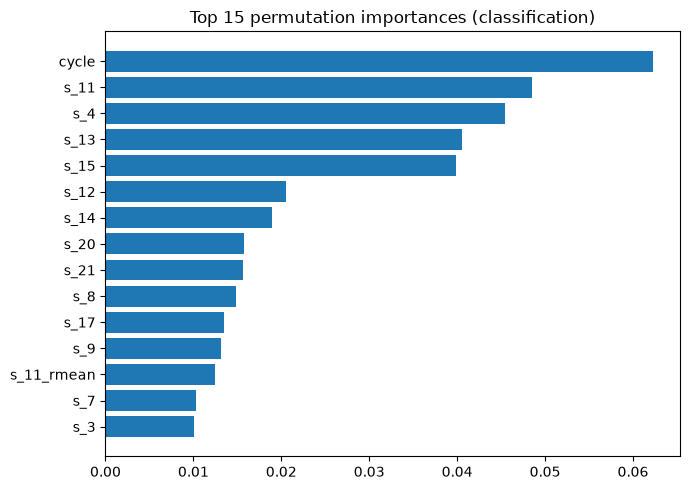

In [17]:
idx = X_valid.sample(n=min(1500, len(X_valid)), random_state=RANDOM_STATE).index
perm = permutation_importance(classifier, X_valid.loc[idx], y_valid.loc[idx], scoring="average_precision",
                              n_repeats=2, random_state=RANDOM_STATE, n_jobs=-1)
class_importance = pd.DataFrame({"feature": X_valid.columns, "importance_mean": perm.importances_mean,
                                 "importance_std": perm.importances_std}).sort_values("importance_mean", ascending=False)
display(class_importance.head(15))
top = class_importance.head(15).iloc[::-1]
plt.figure(figsize=(7, 5)); plt.barh(top.feature, top.importance_mean)
plt.title("Top 15 permutation importances (classification)"); plt.tight_layout(); plt.show()

## 12. Regression: train Random Forest on capped RUL

Same engine-level split as classification, so results are comparable and leakage-free.

In [18]:
yr_train, yr_valid, yr_test = train_df.RUL_capped, valid_df.RUL_capped, test_df.RUL_capped
regressor = RandomForestRegressor(n_estimators=60, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE)
regressor.fit(X_train, yr_train)
print("Trained.")

Trained.


## 13. Regression: evaluation metrics

$$MAE=\frac1n\sum|y_i-\hat y_i|,\quad RMSE=\sqrt{\frac1n\sum(y_i-\hat y_i)^2},\quad R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$$

MAE and RMSE are in cycles. The model is compared with a median baseline.

,value
RF_MAE_cycles,11.228136
RF_RMSE_cycles,15.903187
RF_R2,0.852299
Baseline_MAE_cycles,34.693712
Baseline_RMSE_cycles,47.682912
Test_rows,31330.000000
Test_engines,142.000000


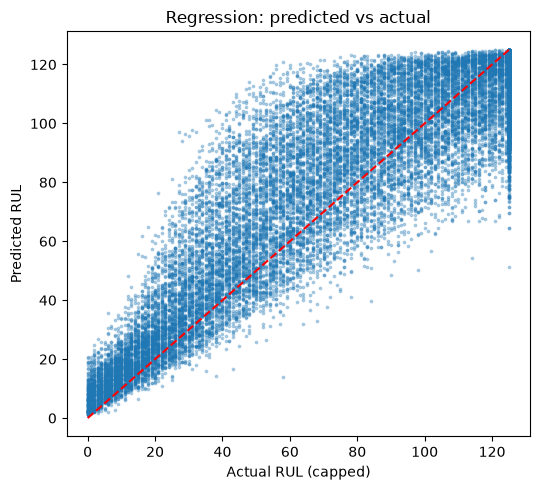

In [19]:
reg_pred = regressor.predict(X_test)
dummy = DummyRegressor(strategy="median").fit(X_train, yr_train)
dummy_pred = dummy.predict(X_test)
regression_metrics = {
    "RF_MAE_cycles": mean_absolute_error(yr_test, reg_pred),
    "RF_RMSE_cycles": mean_squared_error(yr_test, reg_pred) ** 0.5,
    "RF_R2": r2_score(yr_test, reg_pred),
    "Baseline_MAE_cycles": mean_absolute_error(yr_test, dummy_pred),
    "Baseline_RMSE_cycles": mean_squared_error(yr_test, dummy_pred) ** 0.5,
    "Test_rows": int(len(yr_test)), "Test_engines": int(test_df.unit_id.nunique())}
display(pd.Series(regression_metrics).to_frame("value"))

plt.figure(figsize=(5.5, 5)); plt.scatter(yr_test, reg_pred, s=3, alpha=0.3)
plt.plot([0, RUL_CAP], [0, RUL_CAP], "r--"); plt.xlabel("Actual RUL (capped)"); plt.ylabel("Predicted RUL")
plt.title("Regression: predicted vs actual"); plt.tight_layout(); plt.show()

## 14. Official NASA test set evaluation

NASA provides separate test trajectories (truncated before failure) and true RUL values (`RUL_FD00x.txt`). The final recorded cycle of each test engine is predicted and compared with the official RUL. This is an independent check on engines never used in training.

In [20]:
test_fe = engineer(test_raw)
last = test_fe.sort_values("cycle").groupby("unit_id").tail(1).merge(rul_true, on="unit_id")
Xo = prep(make_X(last))
off_rul_pred = regressor.predict(Xo)
off_true = last["RUL"].clip(upper=RUL_CAP)
off_class_true = (last["RUL"] <= HORIZON).astype(int)
off_prob = classifier.predict_proba(Xo)[:, 1]
official_metrics = {
    "Engines": int(len(last)),
    "Regression_MAE_cycles": mean_absolute_error(off_true, off_rul_pred),
    "Regression_RMSE_cycles": mean_squared_error(off_true, off_rul_pred) ** 0.5,
    "Regression_R2": r2_score(off_true, off_rul_pred),
    "Class_ROC_AUC": roc_auc_score(off_class_true, off_prob),
    "Class_Recall_at_threshold": recall_score(off_class_true, (off_prob >= selected_threshold).astype(int)),
    "Class_Precision_at_threshold": precision_score(off_class_true, (off_prob >= selected_threshold).astype(int), zero_division=0)}
display(pd.Series(official_metrics).to_frame("value"))

,value
Engines,707.000000
Regression_MAE_cycles,13.132230
Regression_RMSE_cycles,17.504541
Regression_R2,0.827010
Class_ROC_AUC,0.985057
Class_Recall_at_threshold,0.861635
Class_Precision_at_threshold,0.889610


## 15. Compare classification and regression

Classification predicts a category and uses ROC-AUC, precision, recall and F1. Regression predicts a number of cycles and uses MAE/RMSE/R². The metrics are in different units and should not be compared directly.

In [21]:
display(pd.DataFrame([classification_metrics], index=["Classification"]))
display(pd.DataFrame([regression_metrics], index=["Regression"]))

,ROC_AUC,Average_Precision,Precision,Recall,F1,Test_rows,Test_engines,Threshold
Classification,0.989475,0.948026,0.880019,0.851431,0.865489,31330,142,0.58816


,RF_MAE_cycles,RF_RMSE_cycles,RF_R2,Baseline_MAE_cycles,Baseline_RMSE_cycles,Test_rows,Test_engines
Regression,11.228136,15.903187,0.852299,34.693712,47.682912,31330,142


## 16. Save models and results

In [22]:
joblib.dump(classifier, OUTPUT_DIR / "classification_model.joblib")
joblib.dump(regressor, OUTPUT_DIR / "regression_model.joblib")
class_importance.to_csv(OUTPUT_DIR / "classification_permutation_importance.csv", index=False)
pd.DataFrame({"unit_id": test_df.unit_id.values, "cycle": test_df.cycle.values,
              "actual_RUL_capped": yr_test.values, "predicted_RUL": reg_pred}).to_csv(OUTPUT_DIR / "regression_test_predictions.csv", index=False)
def clean(d): return {k: float(v) if isinstance(v, (np.floating, float, np.integer, int)) else v for k, v in d.items()}
with open(OUTPUT_DIR / "metrics.json", "w") as f:
    json.dump({"classification": clean(classification_metrics), "regression": clean(regression_metrics),
               "official_test": clean(official_metrics)}, f, indent=2)
print("Saved to", OUTPUT_DIR.resolve())

Saved to C:\Users\manoj\Downloads\outputs


## 17. Conclusion

This activity applies classification and regression to NASA C-MAPSS turbofan run-to-failure data. The classifier predicts whether an engine fails within 30 cycles; the regressor estimates remaining useful life. The workflow covers data loading, inspection, target construction, rolling-window feature engineering, an engine-level split to prevent leakage, threshold selection on validation data, evaluation on a held-out test set and on NASA's official test trajectories, permutation importance and model saving.

**Limitations:** the data is simulated, not field data; the RUL cap of 125 and the 30-cycle horizon are design choices; Random Forest is a baseline and sequence models (LSTM, etc.) may perform better.